# 03. Làm sạch dữ liệu
Đầu vào: `data/interim/gop_6_nguon.parquet` (6 nguồn đã ghép, chưa bỏ dòng nào). Các bước:

1. Loại tin không thuộc phạm vi (cho thuê, kho xưởng, văn phòng...)
2. Sửa lỗi định dạng và lỗi đơn vị (mất dấu thập phân, giá lệch 10/100/1000 lần, giá trị vô lý)
3. Sửa loại bất động sản ghi sai
4. Khôi phục dữ liệu thiếu từ thông tin sẵn có (văn bản tiêu đề/mô tả, toạ độ, mô hình phân loại)
5. Loại dòng thiếu biến mục tiêu, vi phạm miền giá trị
6. Loại trùng lặp (trong từng nguồn và giữa các nguồn)
7. Loại ngoại lai giá/m² theo từng khu vực, loại nhà

Mỗi bước đều được ghi vào **nhật ký làm sạch** (số dòng trước/sau). Việc điền giá trị thiếu bằng thống kê (trung vị, KNN...) cho các cột còn lại được làm ở notebook 05, **chỉ fit trên tập huấn luyện** để tránh rò rỉ dữ liệu.

In [1]:
import sys, os, re, time
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score
from xu_ly_chuoi import *

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 70)
sns.set_theme(style='whitegrid')
FIG = '../reports/figures'
os.makedirs(FIG, exist_ok=True)
os.makedirs('../data/processed', exist_ok=True)

np.seterr(divide='ignore', invalid='ignore')
df = pd.read_parquet('../data/interim/gop_6_nguon.parquet')
nhat_ky = []
sua = {'Địa danh, tiêu đề khác mã Unicode / kiểu bỏ dấu -> chuẩn hoá': int(pd.read_csv('../reports/chuan_hoa_unicode.csv')['Số ô đã đổi'].sum())}
def ghi(buoc, truoc, sau, ghi_chu=''):
    nhat_ky.append({'Bước': buoc, 'Trước': truoc, 'Sau': sau, 'Bỏ đi': truoc - sau, 'Ghi chú': ghi_chu})
    print(f'{buoc}: {truoc:,} -> {sau:,} (bỏ {truoc - sau:,}) {ghi_chu}')

ban_dau = df.copy(deep=False)[['nguon', 'gia_vnd', 'dien_tich_m2']]
print('Kích thước ban đầu:', df.shape)

Kích thước ban đầu: (1429399, 28)


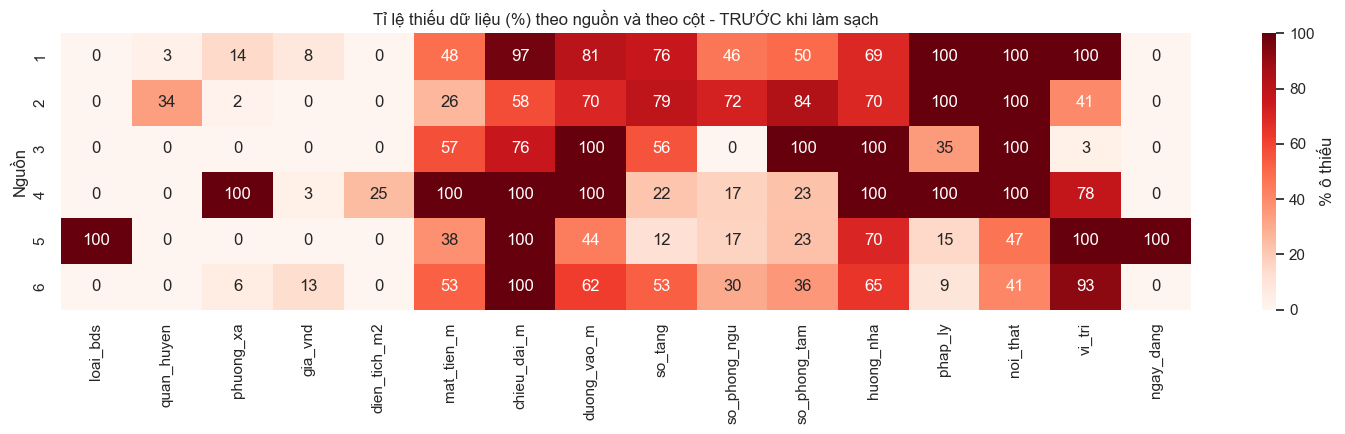

In [2]:
COT_XEM = ['loai_bds', 'quan_huyen', 'phuong_xa', 'gia_vnd', 'dien_tich_m2', 'mat_tien_m', 'chieu_dai_m', 'duong_vao_m',
           'so_tang', 'so_phong_ngu', 'so_phong_tam', 'huong_nha', 'phap_ly', 'noi_that', 'vi_tri', 'ngay_dang']
thieu_truoc = df.groupby('nguon')[COT_XEM].agg(lambda s: s.isna().mean() * 100)
plt.figure(figsize=(15, 4.5))
sns.heatmap(thieu_truoc, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': '% ô thiếu'})
plt.title('Tỉ lệ thiếu dữ liệu (%) theo nguồn và theo cột - TRƯỚC khi làm sạch')
plt.ylabel('Nguồn')
plt.tight_layout()
plt.savefig(f'{FIG}/03_thieu_truoc.png', dpi=120)
plt.show()

## 1. Loại tin không thuộc phạm vi bài toán
Đề tài dự đoán **giá bán nhà ở/đất ở**, nên bỏ: tin cho thuê lọt vào (tiêu đề "cho thuê", không có chữ "bán", giá dạng tiền thuê theo tháng), kho xưởng, văn phòng, khách sạn, nhà trọ và dòng không xác định được tỉnh.

In [3]:
td = df['tieu_de'].fillna('').str.lower()
tin_thue = (td.str.contains('cho thuê') & ~td.str.contains(r'\bbán\b|sang nhượng|chuyển nhượng')
            & ((df['gia_vnd'] < 2e8) | td.str.contains(r'/\s*(?:tháng|th)\b')))
print('Ví dụ tin cho thuê:', df.loc[tin_thue, 'tieu_de'].head(3).tolist())
n = len(df); df = df[~tin_thue]; ghi('1a. Bỏ tin cho thuê', n, len(df))
n = len(df); df = df[~df['loai_bds'].isin(['Kho/Xưởng', 'Thương mại khác'])]; ghi('1b. Bỏ kho xưởng, văn phòng, khách sạn, nhà trọ', n, len(df))
n = len(df); df = df[df['tinh'].notna()]; ghi('1c. Bỏ dòng không xác định được tỉnh', n, len(df))

Ví dụ tin cho thuê: ['Chính chủ cho thuê nhà nguyên căn 2PN, Hẻm Bê tông 4m Quang Trung - Gần Thống Nhất, GV', 'TT 510tr, góp max 14tr/th, cho thuê 12tr/th có nhà trong KCN Phước Đông 1 trệt 1 lầu Lh [phone_number]', '[Gọi Bi ] cặp đất 2 mặt tiền Võ Nguyên Giáp - Đang cho thuê 50 triệu/tháng']


1a. Bỏ tin cho thuê: 1,429,399 -> 1,426,102 (bỏ 3,297) 


1b. Bỏ kho xưởng, văn phòng, khách sạn, nhà trọ: 1,426,102 -> 1,417,722 (bỏ 8,380) 


1c. Bỏ dòng không xác định được tỉnh: 1,417,722 -> 1,417,710 (bỏ 12) 


## 2. Sửa lỗi định dạng và lỗi đơn vị
### 2a. Toạ độ bị mất dấu thập phân hoặc đảo vĩ độ/kinh độ
Ví dụ vĩ độ `23364319310` thực chất là `23.364319310`. Dời dấu thập phân cho tới khi giá trị rơi vào khung Việt Nam (vĩ độ 8–24, kinh độ 102–110); nếu vĩ độ và kinh độ bị đảo thì đổi chỗ; còn lại ngoài khung thì coi là thiếu.

In [4]:
def doi_thap_phan(x, lo, hi):
    if pd.isna(x) or x <= 0:
        return np.nan
    while x > hi:
        x /= 10
    return x if lo <= x <= hi else np.nan

lat0, lon0 = df['vi_do'].copy(), df['kinh_do'].copy()
dao = (lat0 > 100) & (lat0 < 115) & (lon0 > 7) & (lon0 < 25)
df.loc[dao, ['vi_do', 'kinh_do']] = df.loc[dao, ['kinh_do', 'vi_do']].values
df['vi_do'] = df['vi_do'].map(lambda x: doi_thap_phan(x, 8, 24))
df['kinh_do'] = df['kinh_do'].map(lambda x: doi_thap_phan(x, 102, 110))
sua['Toạ độ bị đảo / mất dấu thập phân -> sửa'] = int(dao.sum() + ((lat0 > 24) & df['vi_do'].notna()).sum() + ((lon0 > 110) & df['kinh_do'].notna()).sum())
print('Đổi chỗ vĩ/kinh độ:', int(dao.sum()))
print('Sửa mất dấu thập phân:', int(((lat0 > 24) & df['vi_do'].notna()).sum() + ((lon0 > 110) & df['kinh_do'].notna()).sum()))
print('Toạ độ ngoài Việt Nam -> thiếu:', int((lat0.notna() & df['vi_do'].isna()).sum()))

Đổi chỗ vĩ/kinh độ: 27
Sửa mất dấu thập phân: 441
Toạ độ ngoài Việt Nam -> thiếu: 15


### 2b. Giá trị số vô lý → coi là thiếu (sẽ điền ở notebook 05)

In [5]:
GIOI_HAN = {'so_tang': (1, 50), 'so_phong_ngu': (1, 30), 'so_phong_tam': (1, 30),
            'mat_tien_m': (1, 100), 'chieu_dai_m': (1, 300), 'duong_vao_m': (0.5, 100)}
bang = []
for c, (lo, hi) in GIOI_HAN.items():
    sai = df[c].notna() & ~df[c].between(lo, hi)
    bang.append({'Cột': c, 'Miền hợp lệ': f'{lo} – {hi}', 'Số giá trị vô lý': int(sai.sum()), 'Lớn nhất trước khi sửa': df[c].max()})
    df.loc[sai, c] = np.nan
mat_tien_qua_lon = df['mat_tien_m'].notna() & df['dien_tich_m2'].notna() & (df['mat_tien_m'] > df['dien_tich_m2'])
df.loc[mat_tien_qua_lon, 'mat_tien_m'] = np.nan
bang.append({'Cột': 'mat_tien_m', 'Miền hợp lệ': 'mặt tiền ≤ diện tích', 'Số giá trị vô lý': int(mat_tien_qua_lon.sum()), 'Lớn nhất trước khi sửa': np.nan})
hinh_hoc = (df[['mat_tien_m', 'chieu_dai_m', 'dien_tich_m2']].notna().all(axis=1)
            & ((df['mat_tien_m'] * df['chieu_dai_m'] / df['dien_tich_m2']).sub(1).abs() > 2))
df.loc[hinh_hoc, ['mat_tien_m', 'chieu_dai_m']] = np.nan
bang.append({'Cột': 'mat_tien × chieu_dai', 'Miền hợp lệ': 'không lệch quá 3 lần diện tích', 'Số giá trị vô lý': int(hinh_hoc.sum()), 'Lớn nhất trước khi sửa': np.nan})
sua['Giá trị số vô lý -> đánh dấu thiếu'] = int(sum(b['Số giá trị vô lý'] for b in bang))
pd.DataFrame(bang)

,Cột,Miền hợp lệ,Số giá trị vô lý,Lớn nhất trước khi sửa
0,so_tang,1 – 50,1971,9.191688e+08
1,so_phong_ngu,1 – 30,1249,2.022400e+04
2,so_phong_tam,1 – 30,984,2.550000e+02
3,mat_tien_m,1 – 100,3543,2.000000e+06
4,chieu_dai_m,1 – 300,515,2.109633e+11
5,duong_vao_m,0.5 – 100,576,3.572020e+11
6,mat_tien_m,mặt tiền ≤ diện tích,796,NaN
7,mat_tien × chieu_dai,không lệch quá 3 lần diện tích,1469,NaN


### 2c. Giá lệch đúng 10, 100, 1000 lần (sai đơn vị khi nhập)
Với tin vừa có giá trong cột giá vừa có giá đọc được từ tiêu đề/mô tả mà hai giá trị lệch nhau đúng một luỹ thừa của 10, chọn giá cho ra **giá/m² gần với trung vị giá/m² của cùng loại nhà, cùng quận** hơn.

In [6]:
def trung_vi_nhom(log_gia_m2, khung):
    med_q = log_gia_m2.groupby([khung['loai_bds'], khung['tinh'], khung['quan_huyen'].fillna('?')]).transform('median')
    med_t = log_gia_m2.groupby([khung['loai_bds'], khung['tinh']]).transform('median')
    dem_q = log_gia_m2.groupby([khung['loai_bds'], khung['tinh'], khung['quan_huyen'].fillna('?')]).transform('count')
    return med_q.where(dem_q >= 30, med_t)

lg = np.log10(df['gia_vnd'] / df['dien_tich_m2'])
med = trung_vi_nhom(lg, df)
ti_le = np.log10(df['gia_vnd'] / df['gia_trich_xuat'])
nghi_ngo = ti_le.notna() & (ti_le - ti_le.round()).abs().lt(0.03) & ti_le.round().ne(0)
lg_tx = np.log10(df['gia_trich_xuat'] / df['dien_tich_m2'])
dung_trich_xuat = nghi_ngo & ((lg_tx - med).abs() < (lg - med).abs())
print('Cặp giá lệch đúng luỹ thừa 10:', int(nghi_ngo.sum()), '| mức lệch:', ti_le[nghi_ngo].round().value_counts().sort_index().to_dict())
print('Chọn giá đọc từ văn bản:', int(dung_trich_xuat.sum()), '| giữ giá trong cột giá:', int((nghi_ngo & ~dung_trich_xuat).sum()))
print(df.loc[dung_trich_xuat, ['tieu_de', 'gia_vnd', 'gia_trich_xuat', 'dien_tich_m2']].head(6).to_string())
df.loc[dung_trich_xuat, 'gia_vnd'] = df.loc[dung_trich_xuat, 'gia_trich_xuat']
sua['Giá lệch 10/100/1000 lần -> sửa'] = int(dung_trich_xuat.sum())

Cặp giá lệch đúng luỹ thừa 10: 18303 | mức lệch: {-6.0: 2, -5.0: 1, -4.0: 10, -3.0: 273, -2.0: 280, -1.0: 384, 1.0: 11452, 2.0: 5660, 3.0: 233, 4.0: 7, 6.0: 1}
Chọn giá đọc từ văn bản: 16154 | giữ giá trong cột giá: 2149
                                                                                                      tieu_de       gia_vnd  gia_trich_xuat  dien_tich_m2
24                                    Cực hiếm - lô đất 2 mặt tiền đường hói kiểng 19, diện tích khủng 264.5m  1.568000e+07    1.568000e+10         264.0
7101                               Đất vàng Liên Hà, Thạch Hạ diện tích khủng, đường rộng 8m, đầu tư sinh lời  2.000000e+07    2.000000e+09         247.0
8164   Bán căn 5PN Duplex Mandarin Garden, Hoàng Minh Giám, Cầu Giấy 267m2, full đồ, sổ đỏ, LH [phone_number]  2.660000e+11    2.600000e+10         266.4
12852                                           Đất ruộng ven sông Tiền Giang vị trí đắc địa, đầu tư sinh lời  4.626720e+12    4.800000e+08        9639.0
21536    

## 3. Sửa loại bất động sản ghi sai
Nhiều tin được gắn loại "Nhà ở" nhưng tiêu đề lại là bán đất và không hề có số tầng/số phòng. So sánh loại ghi trong dữ liệu với loại suy ra từ tiêu đề:

In [7]:
def loai_tu_tieu_de(t):
    if pd.isna(t):
        return np.nan
    t = bo_dau(t).lower()
    if re.search(r'can ho|chung cu|\bccmn\b|penthouse|duplex', t):
        return 'Căn hộ'
    if re.search(r'biet thu|lien ke|villa', t):
        return 'Biệt thự/Liền kề'
    if re.search(r'^(ban |can ban |chinh chu ban )?(lo |manh |lo goc )?dat\b|\bdat nen\b|\bdat tho cu\b', t) and not re.search(r'\bnha\b|\btang\b|\bcan\b', t):
        return 'Đất'
    if re.search(r'\bnha\b', t):
        return 'Nhà ở'
    return np.nan

theo_tieu_de = df['tieu_de'].map(loai_tu_tieu_de)
print(pd.crosstab(df['loai_bds'], theo_tieu_de.fillna('(không rõ)'), rownames=['Loại ghi trong dữ liệu'], colnames=['Loại theo tiêu đề']))
khong_nha = df[['so_tang', 'so_phong_ngu', 'so_phong_tam']].isna().all(axis=1)
sua_dat = (df['loai_bds'] == 'Nhà ở') & (theo_tieu_de == 'Đất') & khong_nha
sua_can_ho = (df['loai_bds'] == 'Nhà ở') & (theo_tieu_de == 'Căn hộ') & df['so_tang'].isna()
df.loc[sua_dat, 'loai_bds'] = 'Đất'
df.loc[sua_can_ho, 'loai_bds'] = 'Căn hộ'
sua['Loại BĐS ghi sai -> sửa'] = int(sua_dat.sum() + sua_can_ho.sum())
print('\nSửa "Nhà ở" -> "Đất":', int(sua_dat.sum()), '| "Nhà ở" -> "Căn hộ":', int(sua_can_ho.sum()))
print('Ví dụ:', df.loc[sua_dat, 'tieu_de'].head(3).tolist())

Loại theo tiêu đề       (không rõ)  Biệt thự/Liền kề  Căn hộ   Nhà ở     Đất
Loại ghi trong dữ liệu                                                      
Biệt thự/Liền kề             17226             47813    1506   12317      68
Căn hộ                       93524              1428  132413   15010      33
Nhà ở                       199796             11238   15157  449902    1019
Shophouse                    11620               804    1256    3348      25
Đất                         149676             12940    3718   25286  180338



Sửa "Nhà ở" -> "Đất": 496 | "Nhà ở" -> "Căn hộ": 8966
Ví dụ: ['Bán đất vàng Thanh Hóa diện tích 70m2, mặt tiền 4.5m, tiện ích bủa vây, giá chỉ 3 tỷ', 'Bán lô đất ngay Thái Ly- Quốc Hương Thảo Điền Quận 2 DT:8,8 x 25m (212m2) được xây cao Giá 48 tỷ', 'Bán đất phố Minh Khai, Hai Bà Trưng, Hà Nội, 22 tỷ, 110 m2. Ô tô đỗ cổng']


## 4. Khôi phục dữ liệu thiếu từ thông tin sẵn có
### 4a. Giá và diện tích đọc từ tiêu đề/mô tả
Hàm `gia_tu_van_ban` đã được kiểm chứng ở notebook 02 (khớp ~90% với giá có sẵn, sai số ≤ 5%).

In [8]:
m = df['gia_vnd'].isna() & df['gia_trich_xuat'].notna()
df.loc[m, 'gia_vnd'] = df.loc[m, 'gia_trich_xuat']
sua['Giá thiếu -> khôi phục từ tiêu đề/mô tả'] = int(m.sum())
print('Khôi phục giá từ văn bản:', int(m.sum()), '| còn thiếu giá:', int(df['gia_vnd'].isna().sum()))
m = df['dien_tich_m2'].isna() & df['dien_tich_trich_xuat'].notna()
df.loc[m, 'dien_tich_m2'] = df.loc[m, 'dien_tich_trich_xuat']
sua['Diện tích thiếu -> khôi phục từ tiêu đề'] = int(m.sum())
print('Khôi phục diện tích từ tiêu đề:', int(m.sum()), '| còn thiếu diện tích:', int(df['dien_tich_m2'].isna().sum()))

Khôi phục giá từ văn bản: 22693 | còn thiếu giá: 59058
Khôi phục diện tích từ tiêu đề: 6763 | còn thiếu diện tích: 9961


### 4b. Quận/huyện của tin ghi theo địa giới mới (sau sáp nhập 07/2025)
Các tin này chỉ có phường mới + tỉnh mới, mất cấp quận/huyện – một đặc trưng rất quan trọng với giá. Khôi phục theo 2 cách:
1. Đọc tên quận/huyện cũ còn sót trong tiêu đề ("...tại Xã Tân Bình **Huyện Bắc Tân Uyên**"), chỉ nhận nếu tên đó có thật trong danh sách quận của tỉnh.
2. Với tin còn lại có toạ độ: dùng **KNN theo toạ độ** học từ các tin đã biết quận.

In [9]:
TU_KHOA_QUAN = re.compile(r'(?:^|\s)(Quận|Huyện|Thị xã|Thành phố|TP\.?|Tp\.?)\s+')
def quan_tu_tieu_de(t):
    if pd.isna(t):
        return np.nan
    t = str(t)
    for m in TU_KHOA_QUAN.finditer(t):
        lay = []
        for w in t[m.end():].split():
            w2 = w.strip(',.;:-–()')
            if not w2:
                break
            if w2[0].isdigit() and not lay:
                lay.append(w2)
                break
            if not w2[0].isupper():
                break
            lay.append(w2)
            if w != w2:
                break
        if lay:
            return ' '.join(lay[:4])
    return np.nan

thieu_q = df['quan_huyen'].isna()
print('Thiếu quận/huyện trước khi khôi phục:', int(thieu_q.sum()), '| trong đó tin địa giới mới:', int((thieu_q & df['dia_gioi_moi']).sum()))
cap_hop_le = set(df.loc[df['quan_huyen'].notna(), ['tinh', 'quan_huyen']].itertuples(index=False, name=None))
ung_vien = df.loc[thieu_q, 'tieu_de'].map(quan_tu_tieu_de)
ung_vien = pd.Series([chuan_quan(q, t) if pd.notna(q) else np.nan for q, t in zip(ung_vien, df.loc[thieu_q, 'tinh'])], index=ung_vien.index)
hop_le = pd.Series([(t, q) in cap_hop_le for t, q in zip(df.loc[thieu_q, 'tinh'], ung_vien)], index=ung_vien.index)
df.loc[hop_le[hop_le].index, 'quan_huyen'] = ung_vien[hop_le]
sua['Quận/huyện thiếu -> khôi phục từ tiêu đề'] = int(hop_le.sum())
print('Khôi phục từ tiêu đề:', int(hop_le.sum()))

Thiếu quận/huyện trước khi khôi phục: 107478 | trong đó tin địa giới mới: 74900


Khôi phục từ tiêu đề: 33455


In [10]:
co_td = df['vi_do'].notna() & df['kinh_do'].notna()
hoc = df[co_td & df['quan_huyen'].notna()]
can = df[co_td & df['quan_huyen'].isna()]
print('Tin có toạ độ + đã biết quận (dùng để học):', len(hoc), '| tin có toạ độ cần đoán quận:', len(can))
dung, tong, du_doan = 0, 0, {}
for tinh, nhom in hoc.groupby('tinh'):
    if nhom['quan_huyen'].nunique() < 2 or len(nhom) < 50:
        continue
    X, y = nhom[['vi_do', 'kinh_do']].values, nhom['quan_huyen'].values
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=42)
    knn = KNeighborsClassifier(n_neighbors=5, weights='distance').fit(Xa, ya)
    dung += (knn.predict(Xb) == yb).sum(); tong += len(yb)
    muc_tieu = can[can['tinh'] == tinh]
    if len(muc_tieu):
        knn.fit(X, y)
        du_doan.update(dict(zip(muc_tieu.index, knn.predict(muc_tieu[['vi_do', 'kinh_do']].values))))
print(f'Độ chính xác KNN trên tập kiểm tra (20% tin đã biết quận): {dung / tong:.1%} ({tong:,} tin)')
df.loc[list(du_doan), 'quan_huyen'] = pd.Series(du_doan)
sua['Quận/huyện thiếu -> khôi phục bằng KNN toạ độ'] = len(du_doan)
print('Khôi phục quận bằng KNN toạ độ:', len(du_doan), '| còn thiếu quận:', int(df['quan_huyen'].isna().sum()))
tinh_cu_theo_quan = (df[df['tinh_cu'].notna() & df['quan_huyen'].notna()]
                     .groupby(['tinh', 'quan_huyen'])['tinh_cu'].agg(lambda s: s.mode().iloc[0]))
m = df['tinh_cu'].isna() & df['quan_huyen'].notna()
df.loc[m, 'tinh_cu'] = [tinh_cu_theo_quan.get((t, q), np.nan) for t, q in zip(df.loc[m, 'tinh'], df.loc[m, 'quan_huyen'])]
print('Suy ra tỉnh cũ từ quận:', int(df.loc[m, 'tinh_cu'].notna().sum()))

Tin có toạ độ + đã biết quận (dùng để học): 30156 | tin có toạ độ cần đoán quận: 45101


Độ chính xác KNN trên tập kiểm tra (20% tin đã biết quận): 97.8% (6,008 tin)
Khôi phục quận bằng KNN toạ độ: 44907 | còn thiếu quận: 29116


Suy ra tỉnh cũ từ quận: 74558


### 4c. Loại bất động sản của nguồn 5 (thiếu 100%) – đoán bằng mô hình phân loại
Huấn luyện `HistGradientBoostingClassifier` trên các tin đã biết loại, chỉ dùng **đặc điểm căn nhà** (diện tích, mặt tiền, đường vào, số tầng, số phòng, có thuộc dự án hay không, tỉnh) – **không dùng giá** để tránh rò rỉ thông tin của biến mục tiêu vào đặc trưng.

In [11]:
CAT_TINH = sorted(df['tinh'].unique())
DT_PL = ['dien_tich_m2', 'mat_tien_m', 'duong_vao_m', 'so_tang', 'so_phong_ngu', 'so_phong_tam', 'co_du_an', 'ma_tinh']
def dac_trung_phan_loai(k):
    return pd.DataFrame({'dien_tich_m2': k['dien_tich_m2'], 'mat_tien_m': k['mat_tien_m'], 'duong_vao_m': k['duong_vao_m'],
                         'so_tang': k['so_tang'], 'so_phong_ngu': k['so_phong_ngu'], 'so_phong_tam': k['so_phong_tam'],
                         'co_du_an': k['du_an'].notna().astype(int), 'ma_tinh': pd.Categorical(k['tinh'], categories=CAT_TINH).codes})
biet = df[df['loai_bds'].notna()].sample(300000, random_state=42)
Xa, Xb, ya, yb = train_test_split(dac_trung_phan_loai(biet), biet['loai_bds'], test_size=0.2, random_state=42, stratify=biet['loai_bds'])
clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, categorical_features=[7], random_state=42).fit(Xa, ya)
print(f"Độ chính xác trên tập kiểm tra: {accuracy_score(yb, clf.predict(Xb)):.1%} (đoán toàn bộ là lớp nhiều nhất: {(yb == ya.mode()[0]).mean():.1%})")
thieu_loai = df['loai_bds'].isna()
df.loc[thieu_loai, 'loai_bds'] = clf.predict(dac_trung_phan_loai(df[thieu_loai]))
df['loai_doan'] = thieu_loai
sua['Loại BĐS thiếu (nguồn 5) -> đoán bằng mô hình phân loại'] = int(thieu_loai.sum())
print('Đã đoán loại cho', int(thieu_loai.sum()), 'tin:', df.loc[thieu_loai, 'loai_bds'].value_counts().to_dict())

Độ chính xác trên tập kiểm tra: 86.7% (đoán toàn bộ là lớp nhiều nhất: 48.0%)
Đã đoán loại cho 30249 tin: {'Nhà ở': 25693, 'Biệt thự/Liền kề': 2621, 'Đất': 868, 'Shophouse': 652, 'Căn hộ': 415}


### 4d. Giá trị "không áp dụng" và ngày đăng
- Đất trống không có tầng/phòng: số tầng, số phòng = 0 (không phải thiếu ngẫu nhiên).
- Nguồn 5 không có ngày đăng nhưng biết dữ liệu năm 2024 → gán giữa năm 2024 và đánh dấu là ước lượng.

In [12]:
dat = df['loai_bds'] == 'Đất'
for c in ['so_tang', 'so_phong_ngu', 'so_phong_tam']:
    print(f'{c}: đất trống thiếu -> 0:', int((dat & df[c].isna()).sum()))
    sua[f'{c} của đất trống -> 0 (không áp dụng)'] = int((dat & df[c].isna()).sum())
    df.loc[dat & df[c].isna(), c] = 0
df['ngay_uoc_luong'] = df['ngay_dang'].isna()
df.loc[df['nguon'].eq(5) & df['ngay_dang'].isna(), 'ngay_dang'] = pd.Timestamp('2024-07-01')
df['duong'] = df['duong'].str.strip().str.title()
df['du_an'] = df['du_an'].str.strip()
print('Ngày đăng ước lượng:', int(df['ngay_uoc_luong'].sum()))

so_tang: đất trống thiếu -> 0: 370306
so_phong_ngu: đất trống thiếu -> 0: 371863
so_phong_tam: đất trống thiếu -> 0: 372297


Ngày đăng ước lượng: 31548


## 5. Loại dòng không dùng được
- **Thiếu giá** (biến mục tiêu) hoặc **thiếu diện tích**: không thể điền vì sẽ tạo ra nhãn giả.
- Vi phạm miền giá trị hợp lý: giá ngoài khoảng 100 triệu – 1.000 tỷ; diện tích ngoài khoảng hợp lý của từng loại nhà.

In [13]:
n = len(df); df = df[df['gia_vnd'].notna()]; ghi('5a. Bỏ tin thiếu giá (biến mục tiêu)', n, len(df), 'không thể khôi phục từ văn bản')
n = len(df); df = df[df['dien_tich_m2'].notna()]; ghi('5b. Bỏ tin thiếu diện tích', n, len(df))
MIEN_DT = {'Căn hộ': (15, 1000), 'Nhà ở': (10, 5000), 'Biệt thự/Liền kề': (30, 5000), 'Shophouse': (30, 5000), 'Đất': (20, 10000)}
lo = df['loai_bds'].map(lambda l: MIEN_DT[l][0]); hi = df['loai_bds'].map(lambda l: MIEN_DT[l][1])
hop_le = df['gia_vnd'].between(1e8, 1e12) & df['dien_tich_m2'].between(lo, hi)
print('Giá ngoài miền:', int((~df['gia_vnd'].between(1e8, 1e12)).sum()), '| diện tích ngoài miền:', int((~df['dien_tich_m2'].between(lo, hi)).sum()))
n = len(df); df = df[hop_le]; ghi('5c. Bỏ tin vi phạm miền giá trị', n, len(df), 'giá 0,1–1.000 tỷ; diện tích theo loại')

5a. Bỏ tin thiếu giá (biến mục tiêu): 1,417,710 -> 1,358,652 (bỏ 59,058) không thể khôi phục từ văn bản


5b. Bỏ tin thiếu diện tích: 1,358,652 -> 1,349,492 (bỏ 9,160) 


Giá ngoài miền: 4281 | diện tích ngoài miền: 8077


5c. Bỏ tin vi phạm miền giá trị: 1,349,492 -> 1,337,360 (bỏ 12,132) giá 0,1–1.000 tỷ; diện tích theo loại


## 6. Loại trùng lặp
Cùng một căn được đăng lại nhiều lần trên cùng trang và đăng chéo trên nhiều trang. Khi có trùng, **giữ bản ghi có nhiều thông tin nhất**, nếu bằng nhau thì giữ tin mới nhất.

In [14]:
COT_DT = ['loai_bds', 'quan_huyen', 'phuong_xa', 'duong', 'du_an', 'mat_tien_m', 'chieu_dai_m', 'duong_vao_m', 'so_tang',
          'so_phong_ngu', 'so_phong_tam', 'huong_nha', 'phap_ly', 'noi_that', 'vi_tri', 'vi_do']
df['so_o_co'] = df[COT_DT].notna().sum(axis=1)
df = df.sort_values(['so_o_co', 'ngay_dang'], ascending=False)

n = len(df); df = df.drop_duplicates([c for c in df.columns if c not in ('so_o_co',)]); ghi('6a. Trùng hoàn toàn', n, len(df))
co_ma = df['ma_tin'].notna()
n = len(df); df = df[~(co_ma & df.duplicated(['nguon', 'ma_tin']))]; ghi('6b. Trùng mã tin trong cùng nguồn', n, len(df))
n = len(df); df = df[~(df['tieu_de'].notna() & df.duplicated(['nguon', 'tieu_de', 'gia_vnd', 'dien_tich_m2', 'quan_huyen']))]
ghi('6c. Đăng lại cùng tiêu đề, giá, diện tích, quận', n, len(df))
khoa = pd.DataFrame({'l': df['loai_bds'], 't': df['tinh'], 'q': df['quan_huyen'].fillna('?'),
                     'dt': df['dien_tich_m2'].round(0), 'gia': (df['gia_vnd'] / 1e7).round(0),
                     'pn': df['so_phong_ngu'].fillna(-1), 'tg': df['so_tang'].fillna(-1)})
trung_noi_dung = khoa.duplicated()
so_nguon = khoa.assign(n=df['nguon'].values).groupby(list(khoa.columns))['n'].transform('nunique')
print('Tin bị bỏ vì trùng nội dung:', int(trung_noi_dung.sum()), '| thuộc nhóm có mặt ở >= 2 nguồn (trùng chéo):', int((trung_noi_dung & (so_nguon > 1)).sum()),
      '| chỉ trong 1 nguồn (môi giới khác nhau đăng cùng 1 căn):', int((trung_noi_dung & (so_nguon == 1)).sum()))
n = len(df); df = df[~trung_noi_dung]; ghi('6d. Trùng nội dung (cùng loại, quận, diện tích, giá, số phòng, số tầng)', n, len(df), 'gồm cả trùng chéo giữa các nguồn')

6a. Trùng hoàn toàn: 1,337,360 -> 1,310,773 (bỏ 26,587) 


6b. Trùng mã tin trong cùng nguồn: 1,310,773 -> 1,308,124 (bỏ 2,649) 


6c. Đăng lại cùng tiêu đề, giá, diện tích, quận: 1,308,124 -> 1,219,708 (bỏ 88,416) 


Tin bị bỏ vì trùng nội dung: 333106 | thuộc nhóm có mặt ở >= 2 nguồn (trùng chéo): 120939 | chỉ trong 1 nguồn (môi giới khác nhau đăng cùng 1 căn): 212167


6d. Trùng nội dung (cùng loại, quận, diện tích, giá, số phòng, số tầng): 1,219,708 -> 886,602 (bỏ 333,106) gồm cả trùng chéo giữa các nguồn


## 7. Loại ngoại lai giá/m² theo ngữ cảnh
Cùng 100 triệu/m² là bình thường ở quận trung tâm nhưng vô lý ở huyện ngoại thành, nên không dùng một ngưỡng chung cho cả nước. Với mỗi nhóm (loại nhà, tỉnh, quận) – nếu nhóm quá nhỏ thì dùng (loại nhà, tỉnh) – tính **robust z-score** theo trung vị và MAD của log(giá/m²):

$z = 0.6745\,(x - \text{median}) / \text{MAD}$, loại tin có $|z| > 3.5$ (ngưỡng Iglewicz–Hoaglin). Cách này không bị chính các ngoại lai kéo lệch như trung bình/độ lệch chuẩn.

Số ngoại lai: 23078 (2.60%) | cao bất thường: 10668 | thấp bất thường: 12410
        loai_bds      tinh   quan_huyen                                                                                            tieu_de       gia_vnd  dien_tich_m2
996738    Căn hộ    Hà Nội     Cầu Giấy             Bán CCMN Cầu Giấy - 7 tầng thang máy - 14 phòng khép kín full nội thất - dòng tiền cao  1.920000e+10          53.0
1097627      Đất    Hà Nội     Đông Anh                               Bán nhanh 2 lô đất siêu đẹp tại tàm xá, đông anh, hà nội. giá đầu tư  2.250000e+11         180.0
100824    Căn hộ    Hà Nội  Nam Từ Liêm  Bán ccmn 21 phòng mỹ đình, oto đỗ gần , thang máy 450kg- dòng tiền 100tr/ tháng. giá chỉ 16,7 tỷ.  1.670000e+10          70.0
1250068    Nhà ở    Hà Nội  Nam Từ Liêm                                                                                               None  4.800000e+10          48.0
1376959   Căn hộ    Hà Nội     Hoài Đức                            cần bán CCMN Xuân Phư

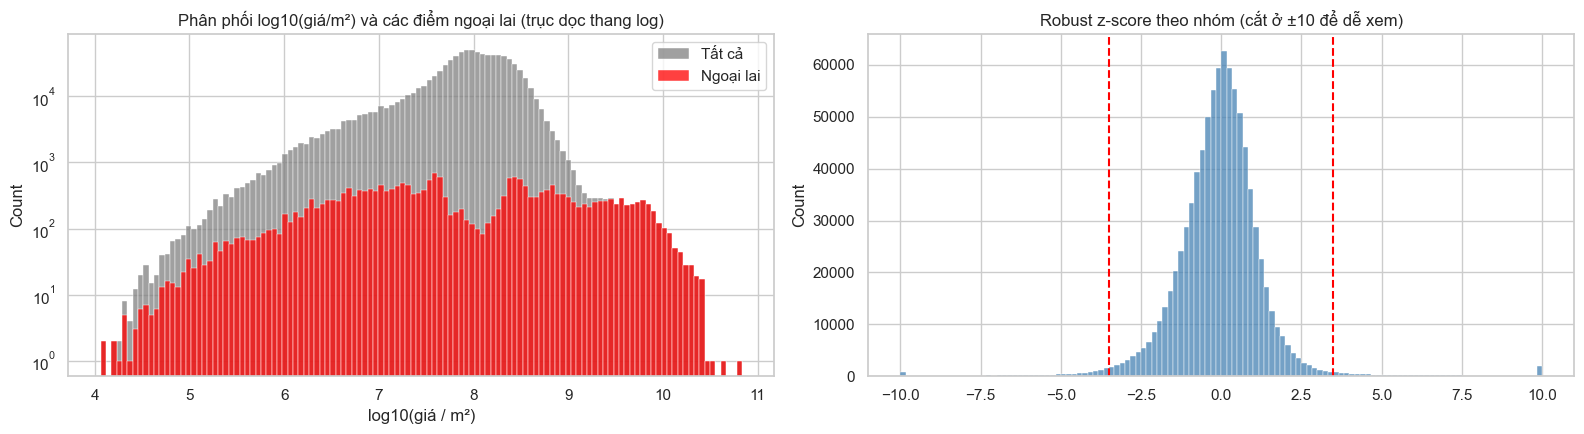

7. Bỏ ngoại lai giá/m² theo nhóm: 886,602 -> 863,524 (bỏ 23,078) robust z > 3.5


In [15]:
x = np.log10(df['gia_vnd'] / df['dien_tich_m2'])
khoa_q = [df['loai_bds'], df['tinh'], df['quan_huyen'].fillna('?')]
khoa_t = [df['loai_bds'], df['tinh']]
med_q, dem_q = x.groupby(khoa_q).transform('median'), x.groupby(khoa_q).transform('count')
mad_q = (x - med_q).abs().groupby(khoa_q).transform('median')
med_t = x.groupby(khoa_t).transform('median')
mad_t = (x - med_t).abs().groupby(khoa_t).transform('median')
dung_q = dem_q >= 50
med, mad = med_q.where(dung_q, med_t), mad_q.where(dung_q, mad_t)
z = 0.6745 * (x - med) / mad.replace(0, np.nan)
ngoai_lai = z.abs() > 3.5
print('Số ngoại lai:', int(ngoai_lai.sum()), f'({ngoai_lai.mean():.2%})', '| cao bất thường:', int((z > 3.5).sum()), '| thấp bất thường:', int((z < -3.5).sum()))
print(df.loc[ngoai_lai, ['loai_bds', 'tinh', 'quan_huyen', 'tieu_de', 'gia_vnd', 'dien_tich_m2']].sample(6, random_state=1).to_string())
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(x, bins=120, ax=ax[0], color='grey', label='Tất cả')
sns.histplot(x[ngoai_lai], bins=120, ax=ax[0], color='red', label='Ngoại lai')
ax[0].set_yscale('log'); ax[0].set_xlabel('log10(giá / m²)'); ax[0].legend(); ax[0].set_title('Phân phối log10(giá/m²) và các điểm ngoại lai (trục dọc thang log)')
sns.histplot(z.clip(-10, 10), bins=120, ax=ax[1], color='steelblue')
ax[1].axvline(3.5, color='red', ls='--'); ax[1].axvline(-3.5, color='red', ls='--')
ax[1].set_title('Robust z-score theo nhóm (cắt ở ±10 để dễ xem)')
plt.tight_layout(); plt.savefig(f'{FIG}/03_ngoai_lai.png', dpi=120); plt.show()
n = len(df); df = df[~ngoai_lai]; ghi('7. Bỏ ngoại lai giá/m² theo nhóm', n, len(df), 'robust z > 3.5')

## 8. Kết quả sau làm sạch
Gồm: nhật ký số dòng sau từng bước, thống kê các ô đã sửa/khôi phục, bảng chất lượng dữ liệu trước – sau, và tỉ lệ thiếu còn lại.

In [16]:
nk = pd.DataFrame(nhat_ky)
nk.loc[len(nk)] = {'Bước': 'TỔNG', 'Trước': len(ban_dau), 'Sau': len(df), 'Bỏ đi': len(ban_dau) - len(df), 'Ghi chú': f'giữ lại {len(df) / len(ban_dau):.1%}'}
nk.to_csv('../reports/nhat_ky_lam_sach.csv', index=False, encoding='utf-8-sig')
nk

,Bước,Trước,Sau,Bỏ đi,Ghi chú
0,1a. Bỏ tin cho thuê,1429399,1426102,3297,
1,"1b. Bỏ kho xưởng, văn phòng, khách sạn, nhà trọ",1426102,1417722,8380,
2,1c. Bỏ dòng không xác định được tỉnh,1417722,1417710,12,
3,5a. Bỏ tin thiếu giá (biến mục tiêu),1417710,1358652,59058,không thể khôi phục từ văn bản
4,5b. Bỏ tin thiếu diện tích,1358652,1349492,9160,
5,5c. Bỏ tin vi phạm miền giá trị,1349492,1337360,12132,"giá 0,1–1.000 tỷ; diện tích theo loại"
6,6a. Trùng hoàn toàn,1337360,1310773,26587,
7,6b. Trùng mã tin trong cùng nguồn,1310773,1308124,2649,
8,"6c. Đăng lại cùng tiêu đề, giá, diện tích, quận",1308124,1219708,88416,
9,"6d. Trùng nội dung (cùng loại, quận, diện tích, giá, số phòng, số ...",1219708,886602,333106,gồm cả trùng chéo giữa các nguồn


In [17]:
bang_sua = pd.DataFrame({'Số ô / số tin': sua})
bang_sua.index.name = 'Sửa lỗi và khôi phục dữ liệu (không bỏ dòng)'
bang_sua.to_csv('../reports/thong_ke_sua_loi.csv', encoding='utf-8-sig')
bang_sua

,Số ô / số tin
Sửa lỗi và khôi phục dữ liệu (không bỏ dòng),
"Địa danh, tiêu đề khác mã Unicode / kiểu bỏ dấu -> chuẩn hoá",68314
Toạ độ bị đảo / mất dấu thập phân -> sửa,468
Giá trị số vô lý -> đánh dấu thiếu,11103
Giá lệch 10/100/1000 lần -> sửa,16154
Loại BĐS ghi sai -> sửa,9462
Giá thiếu -> khôi phục từ tiêu đề/mô tả,22693
Diện tích thiếu -> khôi phục từ tiêu đề,6763
Quận/huyện thiếu -> khôi phục từ tiêu đề,33455
Quận/huyện thiếu -> khôi phục bằng KNN toạ độ,44907


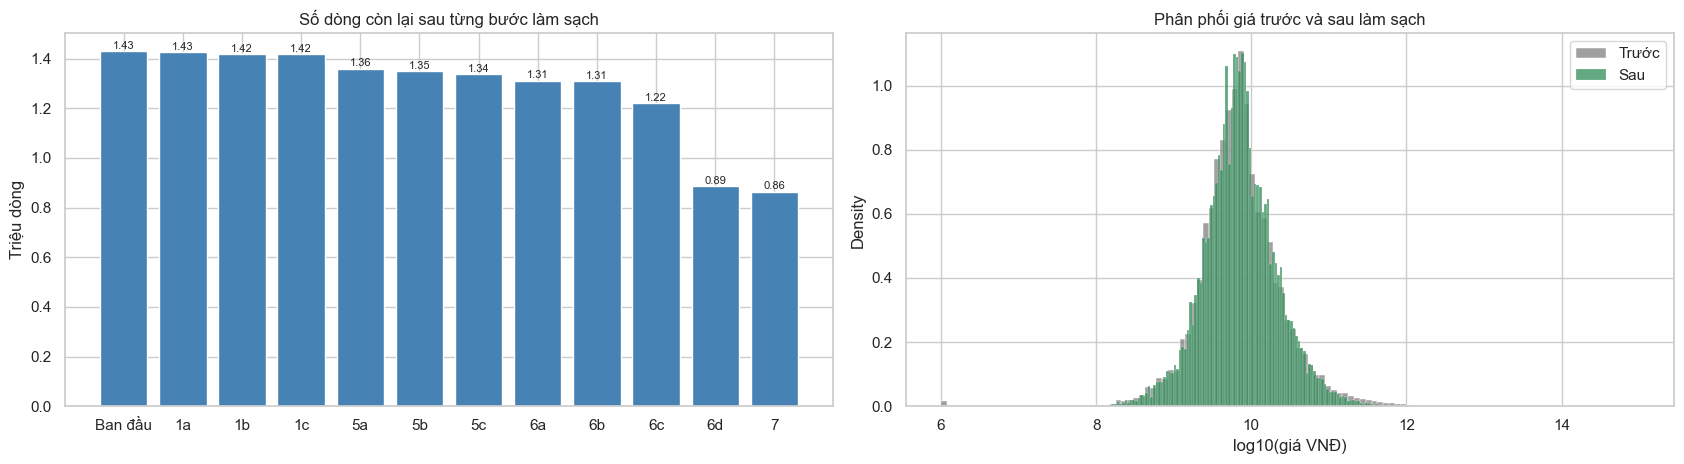

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))
con_lai = [len(ban_dau)] + nk['Sau'].iloc[:-1].tolist()
nhan = ['Ban đầu'] + [b.split('.')[0] for b in nk['Bước'].iloc[:-1]]
ax[0].bar(nhan, np.array(con_lai) / 1e6, color='steelblue')
for i, v in enumerate(con_lai):
    ax[0].text(i, v / 1e6 + 0.01, f'{v / 1e6:.2f}', ha='center', fontsize=8)
ax[0].set_ylabel('Triệu dòng'); ax[0].set_title('Số dòng còn lại sau từng bước làm sạch')
sns.histplot(np.log10(ban_dau['gia_vnd'].clip(1e6, 1e15)), bins=120, ax=ax[1], color='grey', label='Trước', stat='density')
sns.histplot(np.log10(df['gia_vnd']), bins=120, ax=ax[1], color='seagreen', label='Sau', stat='density')
ax[1].set_xlabel('log10(giá VNĐ)'); ax[1].legend(); ax[1].set_title('Phân phối giá trước và sau làm sạch')
plt.tight_layout(); plt.savefig(f'{FIG}/03_ket_qua_lam_sach.png', dpi=120); plt.show()

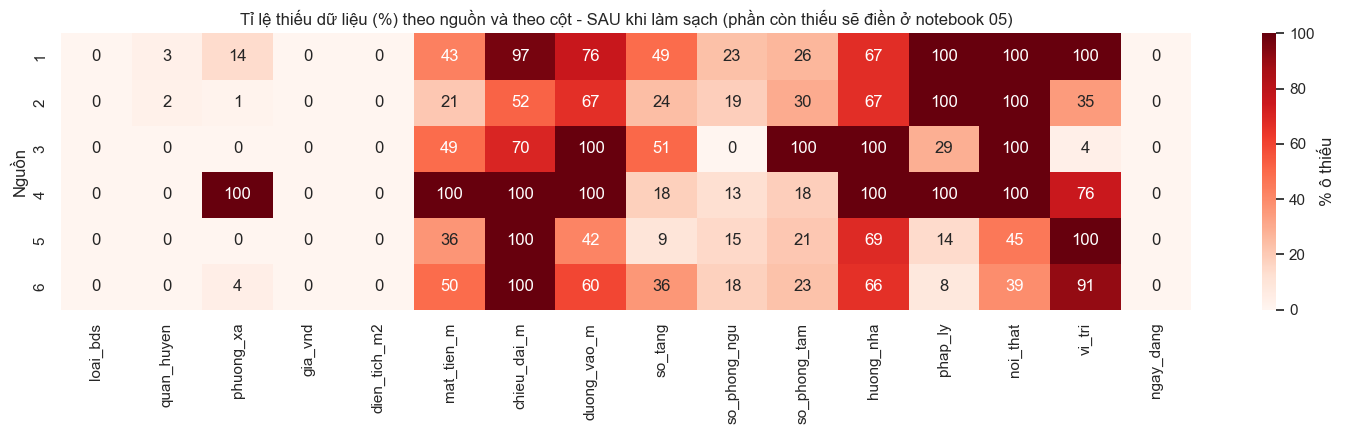

Số dòng theo nguồn sau làm sạch: {1: 594564, 2: 138211, 3: 53955, 4: 42544, 5: 25791, 6: 8459}


In [19]:
thieu_sau = df.groupby('nguon')[COT_XEM].agg(lambda s: s.isna().mean() * 100)
plt.figure(figsize=(15, 4.5))
sns.heatmap(thieu_sau, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=100, cbar_kws={'label': '% ô thiếu'})
plt.title('Tỉ lệ thiếu dữ liệu (%) theo nguồn và theo cột - SAU khi làm sạch (phần còn thiếu sẽ điền ở notebook 05)')
plt.ylabel('Nguồn'); plt.tight_layout(); plt.savefig(f'{FIG}/03_thieu_sau.png', dpi=120); plt.show()
print('Số dòng theo nguồn sau làm sạch:', df['nguon'].value_counts().sort_index().to_dict())

In [20]:
del ban_dau
COT_CL = ['nguon', 'tieu_de', 'loai_bds', 'tinh', 'quan_huyen', 'gia_vnd', 'dien_tich_m2', 'so_tang', 'so_phong_ngu', 'mat_tien_m', 'vi_do']
def chat_luong(k):
    gia_m2 = k['gia_vnd'] / k['dien_tich_m2']
    return {
        'Số dòng': len(k),
        'Thiếu giá (%)': k['gia_vnd'].isna().mean() * 100,
        'Thiếu diện tích (%)': k['dien_tich_m2'].isna().mean() * 100,
        'Thiếu loại BĐS (%)': k['loai_bds'].isna().mean() * 100,
        'Thiếu quận/huyện (%)': k['quan_huyen'].isna().mean() * 100,
        'Giá ngoài 0,1–1.000 tỷ (số tin)': int((k['gia_vnd'].notna() & ~k['gia_vnd'].between(1e8, 1e12)).sum()),
        'Giá/m² ngoài 1–2.000 triệu (số tin)': int((gia_m2.notna() & ~gia_m2.between(1e6, 2e9)).sum()),
        'Số tầng > 50 hoặc phòng ngủ > 30 (số tin)': int(((k['so_tang'] > 50) | (k['so_phong_ngu'] > 30)).sum()),
        'Mặt tiền > 100 m (số tin)': int((k['mat_tien_m'] > 100).sum()),
        'Toạ độ ngoài Việt Nam (số tin)': int((k['vi_do'].notna() & ~k['vi_do'].between(8, 24)).sum()),
        'Tin trùng tiêu đề + giá + diện tích (số tin)': int((k['tieu_de'].notna() & k.duplicated(['tieu_de', 'gia_vnd', 'dien_tich_m2'])).sum()),
    }
goc = pd.read_parquet('../data/interim/gop_6_nguon.parquet', columns=COT_CL)
bang_cl = pd.DataFrame({'Trước làm sạch': chat_luong(goc), 'Sau làm sạch': chat_luong(df)})
del goc
bang_cl.to_csv('../reports/chat_luong_truoc_sau.csv', encoding='utf-8-sig')
bang_cl.style.format('{:,.2f}')

,Trước làm sạch,Sau làm sạch
Số dòng,"1,429,399.00","863,524.00"
Thiếu giá (%),5.76,0.00
Thiếu diện tích (%),1.18,0.00
Thiếu loại BĐS (%),2.12,0.00
Thiếu quận/huyện (%),7.56,2.39
"Giá ngoài 0,1–1.000 tỷ (số tin)","5,891.00",0.00
Giá/m² ngoài 1–2.000 triệu (số tin),"30,057.00","7,226.00"
Số tầng > 50 hoặc phòng ngủ > 30 (số tin),"1,356.00",0.00
Mặt tiền > 100 m (số tin),"3,767.00",0.00
Toạ độ ngoài Việt Nam (số tin),455.00,0.00


In [21]:
df = df.drop(columns=['so_o_co', 'gia_trich_xuat', 'dien_tich_trich_xuat']).reset_index(drop=True)
df['gia_m2'] = df['gia_vnd'] / df['dien_tich_m2']
df.to_parquet('../data/processed/du_lieu_sach.parquet', index=False)
print('Đã lưu data/processed/du_lieu_sach.parquet:', df.shape, '-', round(os.path.getsize('../data/processed/du_lieu_sach.parquet') / 1e6, 1), 'MB')
df.describe(include=[np.number]).T.round(2)

Đã lưu data/processed/du_lieu_sach.parquet: (863524, 29) - 63.5 MB


,count,mean,std,min,25%,50%,75%,max
nguon,863524.0,1.600000e+00,1.100000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,6.000000e+00
gia_vnd,863524.0,1.404297e+10,2.970283e+10,1.000000e+08,3.750000e+09,7.000000e+09,1.380000e+10,1.000000e+12
dien_tich_m2,863524.0,1.928100e+02,6.042700e+02,1.000000e+01,5.200000e+01,7.900000e+01,1.250000e+02,1.000000e+04
mat_tien_m,494509.0,7.500000e+00,7.710000e+00,1.000000e+00,4.050000e+00,5.000000e+00,7.600000e+00,1.000000e+02
chieu_dai_m,101200.0,2.289000e+01,1.961000e+01,1.000000e+00,1.200000e+01,1.800000e+01,2.500000e+01,3.000000e+02
duong_vao_m,206789.0,9.050000e+00,8.730000e+00,5.000000e-01,4.000000e+00,6.000000e+00,1.050000e+01,1.000000e+02
so_tang,496431.0,2.340000e+00,2.400000e+00,0.000000e+00,0.000000e+00,2.000000e+00,4.000000e+00,5.000000e+01
so_phong_ngu,689379.0,2.600000e+00,2.650000e+00,0.000000e+00,0.000000e+00,3.000000e+00,4.000000e+00,3.000000e+01
so_phong_tam,596283.0,2.250000e+00,2.620000e+00,0.000000e+00,0.000000e+00,2.000000e+00,4.000000e+00,3.000000e+01
vi_do,44246.0,1.308000e+01,3.820000e+00,8.750000e+00,1.082000e+01,1.110000e+01,1.271000e+01,2.344000e+01
